# 03 · Feature Engineering — from audited, EDA'd data to model-ready feature stores

Notebooks 01 and 02 established *what the data can support*; this notebook turns those decisions into code: one feature
store per downstream modelling task, every leakage-risk column excluded by construction (not by convention), every
transform justified by a number computed below, and nothing imputed. Outputs are written once, under `data/processed/`,
so notebooks 04-09 read from here rather than re-deriving features independently.

| Part | Input | Output | Feeds |
|---|---|---|---|
| **A** | DS1 (5,500 compounds) | `ds1_material_features.csv` | 04 material property models |
| **B** | DS3 (5,000 bridges) + DS6 (2,000 failures) | `ds3_exposure_features.csv`, `ds6_failure_features.csv`, `ds6_failure_case_control.csv` | 05 failure prediction, 06 financial risk engine (EAD/LGD) |
| **C** | DS2 (8 commodities × ~2,869 days) + DS4 | `ds2_ds4_financial_features.csv` | 06 financial risk engine, 07 scenario stress testing |
| **D** | DS5 (40 elements × 132 months) | `ds5_element_price_features.csv` | 06/07 (cost overlays), joined into Part A |

Conventions carried over from notebooks 01-02: raw files are read-only; every number below is computed from the supplied
files; nothing is deleted or imputed (missing/unavailable stays `NaN` with an availability flag, never filled); every
exclusion is logged as **PROBLEM → DECISION → REASON** in the final section, together with a column-level **feature
manifest** that notebooks 04-09 should treat as the contract for what is safe to use as an input feature, a target, or
neither.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))
from src.data import audit as A
from src.materials import composition as comp_mod
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

RAW, PROC, TAB, FIG = ROOT/"data/raw", ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
for p in (PROC, TAB, FIG): p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42
rng = np.random.default_rng(SEED)
MANIFEST = []   # (dataset, column, role, reason) -- built up through the notebook, saved at the end
DECISIONS = []  # (dataset, PROBLEM, DECISION, REASON) -- mirrors notebook 01's audit log

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

def manifest(dataset, cols, role, reason):
    for c in ([cols] if isinstance(cols, str) else cols):
        MANIFEST.append({"dataset": dataset, "column": c, "role": role, "reason": reason})

def decide(dataset, problem, decision, reason):
    DECISIONS.append({"dataset": dataset, "PROBLEM": problem, "DECISION": decision, "REASON": reason})

dfs = A.load_csvs(RAW); xl = A.load_xlsx_blocks(RAW / A.XLSX_FILE)
d1, d2, d3, d4, d5, d6 = (dfs[k].copy() for k in ["DS1", "DS2", "DS3", "DS4", "DS5", "DS6"])
d1["row_id"] = np.arange(len(d1))   # material_id is NOT unique (audit rule DS1-01) -> row_id is the real key
print({k: v.shape for k, v in dfs.items()})

{'DS1': (5500, 18), 'DS2': (22952, 24), 'DS3': (5000, 24), 'DS4': (22952, 12), 'DS5': (5280, 5), 'DS6': (2000, 18)}


# PART A — DS1: material feature store
*Audit/EDA inputs used here:* `material_id` is duplicated with conflicting formulas (use `row_id`); the physics identity
`E=2G(1+ν)=3K(1-2ν)` is violated in the raw (K,G,ν) triplet but K-G rank correlation is strong (Spearman 0.865), so ν and
E are **derived from (K,G) post-prediction**, never fit as independent targets; `category` alone reaches grouped-CV R² up
to 0.68 (band gap) while raw composition carries ~no signal (0/496 element×property tests significant) — so a leakage-safe
category baseline is worth encoding as a feature; `is_stable` is a deterministic threshold of `energy_above_hull_eV`, so
that column must never feed a model of `is_stable`; density has no reliable physical identity (only 4.7% of rows within
10% of composition-implied density) and `monthly_return` in DS5 is unusable, so returns there are re-derived from price.

## A1 · Composition descriptors and the (weak) density identity
*Question: what do we get for free by parsing the formula — and is the composition-implied density worth keeping as a feature,
given the audit found it only matches the supplied density for 4.7% of rows?*

In [2]:
comp = comp_mod.composition_table(d1.formula)
d1 = pd.concat([d1, comp], axis=1)
d1["density_implied_g_cm3"] = comp_mod.density_from_cell(d1.nsites, d1.mean_atomic_mass, d1.volume_A3)
d1["density_ratio_to_implied"] = d1.density_g_cm3 / d1.density_implied_g_cm3
print("unparsed-element rows:", int((d1.n_unparsed_elements > 0).sum()), "of", len(d1))
print("density ratio (supplied/implied): median=%.2f  within ±10%%: %.1f%%" % (
    d1.density_ratio_to_implied.median(), 100 * (d1.density_ratio_to_implied.sub(1).abs() < .10).mean()))
display(d1[["formula", "mean_atomic_mass", "mean_Z", "atoms_per_formula", "density_g_cm3", "density_implied_g_cm3", "density_ratio_to_implied"]].head(5))
manifest("DS1", ["mean_atomic_mass", "mean_Z", "max_Z", "min_Z", "atoms_per_formula", "n_elements_parsed"], "feature", "composition descriptors parsed from formula; carry little signal per EDA A4 but are the only composition-only features available")
manifest("DS1", ["density_implied_g_cm3", "density_ratio_to_implied"], "feature", "weak: only ~5% of rows match within 10% (EDA A4); kept as a feature, not a replacement for supplied density")
decide("DS1", "density has no reliable physical identity from composition+cell volume (only 4.7% of rows within 10%, audit/EDA)",
       "keep density_implied as an engineered feature, not a substitute target or imputation source",
       "a 95%-wrong identity would corrupt more than it adds if used to fill or validate density")

unparsed-element rows: 0 of 5500
density ratio (supplied/implied): median=2.35  within ±10%: 4.7%


,formula,mean_atomic_mass,mean_Z,atoms_per_formula,density_g_cm3,density_implied_g_cm3,density_ratio_to_implied
0,Ta3Au3H2,141.970125,57.25,8.0,4.343,4.892030,0.887770
1,Al3Rh4W3,104.409000,44.10,10.0,6.757,1.899898,3.556506
2,Pd3Te3,117.010000,49.00,6.0,10.501,1.210137,8.677526
3,Ne4Cd4,66.297000,29.00,8.0,1.754,4.293424,0.408532
4,Al4Rh,42.166800,19.40,5.0,3.360,1.594072,2.107809


## A2 · Physics-derived elastic quantities — post-prediction only, never input features
*Question: ν and E are not independent measurements (they're violated 28.8%/33.5% of the time against the README's own
identity) but K-G are coherent (Spearman 0.865). So K and G become the targets, and ν, E are computed FROM the model's
(K,G) predictions after the fact. Those derived columns must therefore be excluded from the input feature set — including this one.*

In [3]:
d1["nu_from_KG"] = A._poisson_from_KG(d1.bulk_modulus_GPa, d1.shear_modulus_GPa)
d1["E_from_KG_GPa"] = A.young_from_KG(d1.bulk_modulus_GPa, d1.shear_modulus_GPa)
d1["pugh_K_over_G"] = d1.bulk_modulus_GPa / d1.shear_modulus_GPa
d1["is_ductile_pugh"] = d1.pugh_K_over_G > 1.75
print("median |supplied nu - nu_from_KG| =", round((d1.poisson_ratio - d1.nu_from_KG).abs().median(), 4))
print("ductile (Pugh K/G>1.75) share:", round(d1.is_ductile_pugh.mean(), 3))
manifest("DS1", ["nu_from_KG", "E_from_KG_GPa", "pugh_K_over_G", "is_ductile_pugh"], "derived_post_prediction",
         "computed FROM (K,G); apply this formula to a model's K,G predictions to get physics-consistent nu/E — never use as an input feature (circular) and never fit nu/E as independent regression targets")
manifest("DS1", "poisson_ratio", "target_do_not_model_independently", "only ~71% of rows satisfy nu=nu(K,G) within 0.01 (audit DS1-10); report it only as derived from predicted K,G")
manifest("DS1", "energy_above_hull_eV", "exclude_leakage_for_is_stable", "is_stable is a deterministic threshold of this column (EDA A6); using it as a feature for is_stable is leakage by construction")
decide("DS1", "(K,G,nu) triplet mutually inconsistent with the README's own elastic identity in 28.8%/33.5% of rows",
       "predict K and G as primary targets; derive nu and E from the predictions with the isotropic formula (src.data.audit.young_from_KG / _poisson_from_KG)",
       "at most two of (K,G,nu) can be trusted simultaneously; deriving the third enforces the identity by construction instead of fitting a column that contradicts physics")

median |supplied nu - nu_from_KG| = 0.0061
ductile (Pugh K/G>1.75) share: 0.629


## A3 · Which targets need a transform, and the two-part band-gap target
*Question: A1 of the EDA flagged right-skew in several targets by eyeballing histograms. Recompute skew here, decide the
cutoff in code, and check the claim that `is_metal == (band_gap_eV == 0)` exactly — which decides whether band gap needs a
two-part (classify-then-regress) target.*

skew:
 shear_modulus_GPa               1.322
band_gap_eV                     1.272
density_g_cm3                   0.858
bulk_modulus_GPa                0.803
melting_point_K                 0.198
formation_energy_per_atom_eV   -0.714
dtype: float64
-> log1p transform applied to: ['shear_modulus_GPa', 'band_gap_eV']
is_metal == (band_gap_eV==0) exactly: True


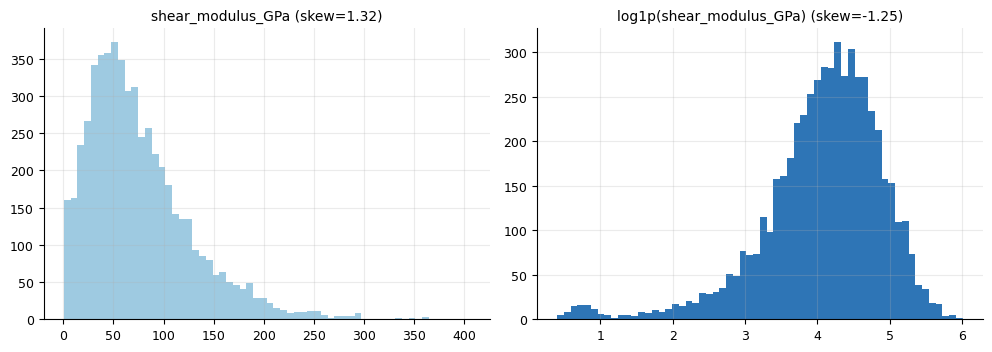

In [4]:
cols = ["bulk_modulus_GPa", "shear_modulus_GPa", "melting_point_K", "band_gap_eV", "formation_energy_per_atom_eV", "density_g_cm3"]
skew = d1[cols].skew().sort_values(ascending=False)
LOG1P_COLS = skew[skew.abs() > 1.0].index.tolist()
print("skew:\n", skew.round(3))
print("-> log1p transform applied to:", LOG1P_COLS)
for c in LOG1P_COLS:
    d1[f"log1p_{c}"] = np.log1p(d1[c])

exact_match = bool((d1.is_metal == (d1.band_gap_eV == 0)).all())
print("is_metal == (band_gap_eV==0) exactly:", exact_match)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(d1.shear_modulus_GPa, bins=60, color="#9ecae1"); ax[0].set_title(f"shear_modulus_GPa (skew={skew['shear_modulus_GPa']:.2f})")
ax[1].hist(d1.log1p_shear_modulus_GPa, bins=60, color="#2e75b6"); ax[1].set_title(f"log1p(shear_modulus_GPa) (skew={d1.log1p_shear_modulus_GPa.skew():.2f})")
savefig("A3_transform_check.png")

manifest("DS1", [f"log1p_{c}" for c in LOG1P_COLS], "target_transform", "log1p variant of a right-skewed target (|skew|>1, computed above); fit on this scale, exponentiate (expm1) predictions back")
manifest("DS1", "is_metal", "feature_and_stage1_target", "exact complement of band_gap_eV==0 (verified above); use as the classifier stage of a two-part band-gap model")
decide("DS1", "band_gap_eV has a point mass at 0 (32.5% of rows, metals) alongside a continuous positive part",
       f"two-part target: classify is_metal (band_gap==0, verified exact match={exact_match}), then regress log1p(band_gap_eV) on the non-metal rows only",
       "a single regressor on the mixed target would have to learn the point mass; splitting matches the data-generating structure exactly")

## A4 · CV-safe category baseline (and nothing else from labels)
*Question: category alone reaches grouped-CV R² of 0.51-0.68 depending on the target (EDA A4) — far above what composition
gives. That is strong enough to be worth encoding as a feature, but a plain `groupby(category).mean()` would leak: 42 rows
share 21 `material_id`s with conflicting formulas, and more rows repeat a `formula` outright. `GroupKFold` on `formula`
keeps every repeated formula in a single fold, same as the EDA's own benchmark, so the out-of-fold category mean below
cannot leak through either duplicate.*

In [5]:
def group_kfold_target_encode(df, cat_col, target_col, groups, n_splits=5):
    oof = pd.Series(np.nan, index=df.index, dtype=float)
    for tr_idx, te_idx in GroupKFold(n_splits=n_splits).split(df, groups=groups):
        means = df.iloc[tr_idx].groupby(cat_col)[target_col].mean()
        global_mean = df.iloc[tr_idx][target_col].mean()
        oof.iloc[te_idx] = df.iloc[te_idx][cat_col].map(means).fillna(global_mean).values
    return oof

TARGETS_D1 = ["bulk_modulus_GPa", "shear_modulus_GPa", "formation_energy_per_atom_eV", "density_g_cm3", "melting_point_K", "band_gap_eV"]
for t in TARGETS_D1:
    d1[f"catmean_{t}"] = group_kfold_target_encode(d1, "category", t, groups=d1.formula)
r2 = {t: 1 - ((d1[t] - d1[f"catmean_{t}"]) ** 2).sum() / ((d1[t] - d1[t].mean()) ** 2).sum() for t in TARGETS_D1}
print("out-of-fold R2 of the category-mean feature alone (sanity check against EDA A4's 0.51-0.68 range):")
display(pd.Series(r2).round(3).to_frame("oof_R2"))
manifest("DS1", [f"catmean_{t}" for t in TARGETS_D1], "feature", "GroupKFold-by-formula out-of-fold category mean; strong baseline feature (EDA A4) that cannot leak through duplicate material_id/formula rows")

out-of-fold R2 of the category-mean feature alone (sanity check against EDA A4's 0.51-0.68 range):


,oof_R2
bulk_modulus_GPa,0.512
shear_modulus_GPa,0.358
formation_energy_per_atom_eV,0.590
density_g_cm3,0.255
melting_point_K,0.358
band_gap_eV,0.676


## A5 · DS5 element prices → a static material cost feature (partial coverage)
*Question: DS5 prices 40 elements; EDA C3 found 32.6% of DS1 materials have every element priced. Build the mass-weighted
$/kg proxy for those materials and leave the rest `NaN` with an explicit availability flag — never impute a cost from a
partially-priced formula.*

coverage: 32.6% of DS1 materials (EDA C3 found 32.6%) | priced at 2024-12-01


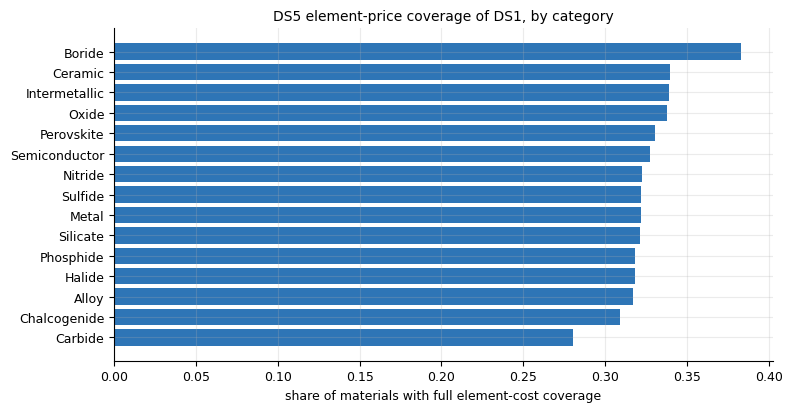

In [6]:
els5 = set(d5.element)
latest_date = d5.date.max()
latest_prices = d5[d5.date == latest_date].set_index("element").price_usd_per_kg

def material_cost_proxy(formula):
    c = A.parse_elements(formula)
    if not c or not set(c) <= els5: return np.nan, False
    total_mass = sum(cnt * comp_mod.ATOMIC_DATA[el][1] for el, cnt in c.items() if el in comp_mod.ATOMIC_DATA)
    if total_mass <= 0: return np.nan, False
    cost = sum(cnt * comp_mod.ATOMIC_DATA[el][1] * latest_prices.get(el, np.nan) for el, cnt in c.items()) / total_mass
    return cost, True

res = [material_cost_proxy(f) for f in d1.formula]
d1["element_cost_usd_per_kg"] = [r[0] for r in res]
d1["element_cost_available"] = [r[1] for r in res]
cov = d1.groupby("category").element_cost_available.mean().sort_values()
print(f"coverage: {d1.element_cost_available.mean():.1%} of DS1 materials (EDA C3 found 32.6%) | priced at {latest_date.date()}")
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.barh(cov.index, cov.values, color="#2e75b6"); ax.set_xlabel("share of materials with full element-cost coverage"); ax.set_title("DS5 element-price coverage of DS1, by category")
savefig("A5_element_cost_coverage.png")
manifest("DS1", ["element_cost_usd_per_kg", "element_cost_available"], "feature", "static (single-date) mass-weighted element cost from DS5; NaN + available=False where any element is unpriced -- never imputed (README's GAN cost-constraint input)")
decide("DS1", "DS5 prices only 40 of the elements appearing in DS1 formulas; coverage is 32.6% of materials",
       "compute the cost feature only for fully-covered materials; carry an explicit element_cost_available flag for the rest",
       "a partial-formula cost (ignoring unpriced elements) would silently understate cost and vary in bias by category")

## A6 · Assemble and save the DS1 feature store

In [7]:
d1.to_csv(PROC / "ds1_material_features.csv", index=False)
manifest("DS1", "row_id", "id", "material_id is duplicated with conflicting formulas (audit DS1-01); row_id is the only reliable key")
manifest("DS1", "material_id", "metadata_not_unique", "42 rows share 21 ids with conflicting formulas -- never join on this column")
manifest("DS1", ["crystal_system", "spacegroup_number", "category", "n_elements", "nsites", "volume_A3"], "feature", "supplied structural/label columns")
manifest("DS1", ["bulk_modulus_GPa", "shear_modulus_GPa", "formation_energy_per_atom_eV", "density_g_cm3", "melting_point_K", "band_gap_eV"], "target", "primary DS1 regression targets named in the README")
manifest("DS1", "is_stable", "target", "classification target; energy_above_hull_eV excluded from its feature set (see A2)")
print("DS1 feature store:", d1.shape, "->", PROC / "ds1_material_features.csv")
print(sorted(d1.columns.tolist()))

DS1 feature store: (5500, 42) -> /home/claude/matrisk_ai/data/processed/ds1_material_features.csv
['E_from_KG_GPa', 'atoms_per_formula', 'band_gap_eV', 'bulk_modulus_GPa', 'category', 'catmean_band_gap_eV', 'catmean_bulk_modulus_GPa', 'catmean_density_g_cm3', 'catmean_formation_energy_per_atom_eV', 'catmean_melting_point_K', 'catmean_shear_modulus_GPa', 'crystal_system', 'density_g_cm3', 'density_implied_g_cm3', 'density_ratio_to_implied', 'element_cost_available', 'element_cost_usd_per_kg', 'energy_above_hull_eV', 'formation_energy_per_atom_eV', 'formula', 'is_ductile_pugh', 'is_metal', 'is_stable', 'log1p_band_gap_eV', 'log1p_shear_modulus_GPa', 'material_id', 'max_Z', 'mean_Z', 'mean_atomic_mass', 'melting_point_K', 'min_Z', 'n_elements', 'n_elements_parsed', 'n_unparsed_elements', 'nsites', 'nu_from_KG', 'poisson_ratio', 'pugh_K_over_G', 'row_id', 'shear_modulus_GPa', 'spacegroup_number', 'volume_A3']


# PART B — DS3 exposure/degradation and DS6 failure/LGD feature stores
*Audit/EDA inputs used here:* `structurally_deficient` is an exact function of `condition_rating<=4` (leakage if both are
used); `remaining_thickness_mm` is exactly `original - corrosion_rate*age` (derived, redundant with `thick_frac`);
`fatigue_cycles_millions` equals `ADT*365*age/1e6` to within 10% for 81.5% of rows (not an independent measurement);
Paris constants are per-material constants with zero within-material variance (redundant with `material`); DS6 contains
**failures only**, so a classifier needs an explicit case-control construction against the DS3 population — correctly
flagged as an *assumption*, not an established fact, exactly as notebook 02 Part C5 did.

## B1 · DS3 degradation and exposure features
*Question: turn the audit's derived-variable findings into one consistent feature set — pick `thick_frac` over the
redundant `remaining_thickness_mm`, drop `fatigue_cycles_millions`/Paris constants as non-independent, and build the
EAD-relevant exposure ratios (LTV, premium rate).*

In [8]:
d3["is_metal"] = d3.paris_m > 0   # data-driven: zero Paris-law fatigue constants for concrete/FRP/timber (audit finding)
d3["thick_frac"] = d3.remaining_thickness_mm / d3.original_thickness_mm
d3["age_ratio"] = d3.age_years / d3.design_life_years
d3["log_corr"] = np.log(d3.corrosion_rate_mm_yr)
d3["condition_rating_clipped"] = d3.condition_rating.clip(lower=1)   # 0 is below the documented 1-9 scale (audit DS3-01)
d3["ltv"] = d3.loan_outstanding_M / d3.replacement_cost_M
d3["cost_per_sqft"] = d3.replacement_cost_M * 1e6 / d3.deck_area_sqft
d3["prem_rate_bps"] = d3.insurance_premium_K_yr * 1e3 / (d3.replacement_cost_M * 1e6) * 1e4
print("is_metal materials:", sorted(d3.loc[d3.is_metal, "material"].unique()))
print("is_metal share:", round(d3.is_metal.mean(), 3), "| condition_rating==0 rows clipped:", int((d3.condition_rating == 0).sum()))

implied_fatigue = d3.adt * 365 * d3.age_years / 1e6
within10 = float((d3.fatigue_cycles_millions / implied_fatigue).sub(1).abs().lt(.10).mean())
print(f"fatigue_cycles_millions within 10% of ADT*365*age/1e6: {within10:.1%} of rows -> excluded as a feature (redundant)")

manifest("DS3", ["material", "bridge_type", "location", "corrosion_environment", "is_metal"], "feature", "categorical drivers (EDA B1: material+environment adj R2=0.77 of log corrosion)")
manifest("DS3", ["age_years", "design_life_years", "age_ratio", "corrosion_rate_mm_yr", "log_corr", "adt", "deck_area_sqft", "tensile_strength_MPa", "yield_strength_MPa"], "feature", "supplied/derived continuous drivers")
manifest("DS3", "thick_frac", "feature", "remaining/original thickness; use INSTEAD of remaining_thickness_mm (see decision below)")
manifest("DS3", "remaining_thickness_mm", "exclude_redundant", "== original_thickness_mm - corrosion_rate_mm_yr*age_years (audit DS3-10); double-counts with thick_frac/corrosion*age")
manifest("DS3", "fatigue_cycles_millions", "exclude_redundant", f"within 10% of ADT*365*age/1e6 for {within10:.1%} of rows (not an independent measurement)")
manifest("DS3", ["paris_C", "paris_m"], "exclude_redundant", "per-material constants (zero within-material variance); information already captured by `material`/`is_metal`")
manifest("DS3", "structurally_deficient", "exclude_leakage_for_condition_rating", "exact function of condition_rating<=4 (audit DS3-08)")
manifest("DS3", "last_inspection_date", "exclude", "earlier than year_built for some rows (audit DS3-11); audit decision was to never use it as a predictor")
manifest("DS3", "condition_rating", "target", "ordinal NBI 1-9 rating / PD-state proxy")
manifest("DS3", ["replacement_cost_M", "loan_outstanding_M", "ltv", "cost_per_sqft"], "feature", "EAD inputs")
manifest("DS3", ["insurance_premium_K_yr", "prem_rate_bps"], "feature_benchmark_only", "not risk-based (EDA D2: rho with condition/corrosion <=0.01); usable only as an order-of-magnitude benchmark, not a training target")
decide("DS3", "remaining_thickness_mm, fatigue_cycles_millions and Paris constants are each deterministic/near-deterministic functions of other columns",
       "keep thick_frac (not remaining_thickness_mm); drop fatigue_cycles_millions and paris_C/paris_m from the model feature list",
       "including both sides of a near-identity inflates apparent signal and collinearity without adding information")

is_metal materials: ['Aluminium Alloy', 'Cast Iron', 'Composite Steel-Concrete', 'Stainless Steel 316L', 'Steel (A36)', 'Steel (A514 HY)', 'Steel (A588 Weathering)']
is_metal share: 0.553 | condition_rating==0 rows clipped: 5
fatigue_cycles_millions within 10% of ADT*365*age/1e6: 81.5% of rows -> excluded as a feature (redundant)


## B2 · Critical-thickness exposure (workbook reference range)
*Question: the CSV has no critical-thickness column; the workbook's 10-asset table gives the only documented
wall/critical-thickness ratios. Use that range to flag bridges already below it and estimate years remaining at the
current corrosion rate — descriptive features, not a trained model.*

workbook critical/original thickness ratio range (10 assets): 0.417 - 0.500
share below_crit_hi: 0.8% | median yrs_to_crit_hi: 436


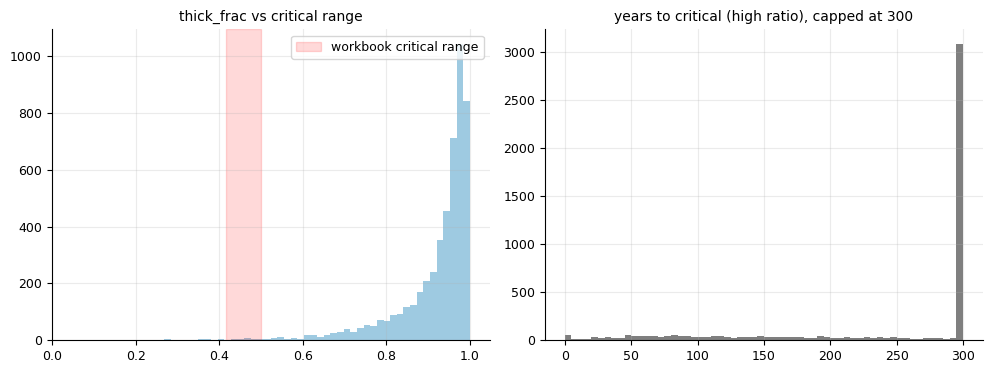

In [9]:
pt = xl["DS3_Infrastructure_Portfolio::block2"]
crit = pd.to_numeric(pt["Critical Thickness (mm)"]) / pd.to_numeric(pt["Wall/Cover Thickness (mm)"])
CR_LO, CR_HI = float(crit.min()), float(crit.max())
print(f"workbook critical/original thickness ratio range (10 assets): {CR_LO:.3f} - {CR_HI:.3f}")
d3["below_crit_lo"] = d3.thick_frac < CR_LO
d3["below_crit_hi"] = d3.thick_frac < CR_HI
d3["yrs_to_crit_hi"] = ((d3.remaining_thickness_mm - CR_HI * d3.original_thickness_mm) / d3.corrosion_rate_mm_yr).clip(lower=0)
print(f"share below_crit_hi: {d3.below_crit_hi.mean():.1%} | median yrs_to_crit_hi: {d3.yrs_to_crit_hi.median():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(d3.thick_frac, bins=60, color="#9ecae1"); ax[0].axvspan(CR_LO, CR_HI, color="red", alpha=.15, label="workbook critical range"); ax[0].legend(); ax[0].set_title("thick_frac vs critical range")
ax[1].hist(d3.yrs_to_crit_hi.clip(upper=300), bins=60, color="#7f7f7f"); ax[1].set_title("years to critical (high ratio), capped at 300")
savefig("B2_critical_thickness.png")
manifest("DS3", ["below_crit_lo", "below_crit_hi", "yrs_to_crit_hi"], "feature", "descriptive exposure-to-critical-thickness features from the workbook's 10-asset reference ratios (EDA B4)")

## B3 · DS6 failure/LGD features and the post-event leakage list
*Question: turn severity into an ordinal feature, cap the loss ratio, and exclude every column that is only known
**after** a failure has been detected and processed — these would leak the outcome into a failure-prediction or
LGD-at-detection model.*

In [10]:
d6["lr_cap"] = d6.loss_ratio.clip(upper=1)
d6["log_repair_cost"] = np.log(d6.repair_cost_USD)
d6["log_replacement_value"] = np.log(d6.replacement_value_USD)
SEVERITY_ORDER = {"Minor": 1, "Moderate": 2, "Major": 3, "Catastrophic": 4}
d6["severity_ord"] = d6.severity.map(SEVERITY_ORDER)
print("loss_ratio>1 (repair>replacement):", f"{(d6.loss_ratio > 1).mean():.1%}", "| mean lr_cap:", round(d6.lr_cap.mean(), 3))

POST_EVENT = ["was_predicted", "warning_lead_months", "detected_by", "insurance_claim_filed", "regulatory_action"]
manifest("DS6", POST_EVENT, "exclude_leakage", "known only after the failure was detected/processed (audit); must not feed a failure-occurrence, severity or LGD-at-event model")
manifest("DS6", ["structure_type", "material", "location", "corrosion_environment", "age_at_event_years", "corrosion_rate_mm_yr"], "feature", "pre-event descriptors")
manifest("DS6", "failure_mode", "feature_weak", "statistically independent of material/structure/environment (EDA C2, Cramer's V<=0.045); keep as a descriptive column, expect little predictive value")
manifest("DS6", ["severity", "severity_ord"], "target", "severity explains 90% of loss-ratio rank variance (EDA D3); the real LGD driver")
manifest("DS6", ["loss_ratio", "lr_cap", "log_repair_cost", "log_replacement_value"], "target", "LGD targets, capped and uncapped variants (audit decision: report both)")
decide("DS6", f"{len(POST_EVENT)} columns (was_predicted, warning_lead_months, detected_by, insurance_claim_filed, regulatory_action) are only known after a failure is detected/processed",
       "exclude all five from any pre-event feature set (failure occurrence, severity, or LGD-at-event models)",
       "using post-event information to predict the event (or its severity) is leakage, even though the columns are real and useful for other purposes (e.g. a claims-process notebook)")

loss_ratio>1 (repair>replacement): 4.2% | mean lr_cap: 0.291


## B4 · Case-control failure dataset (DS3 population vs DS6 bridge failures) — an explicit assumption
**Assumption under test, not established by the data (same one EDA Part C5 flagged):** DS3's 5,000 bridges are
representative of the population that generated DS6's 1,011 *bridge* failures. There is no asset-level key between them
— only a shared categorical/numeric feature space (material, environment, location, age, corrosion rate). The table
below is built on that assumption so notebook 05 has something to train a classifier on; it must not be read as a
confirmed cohort link.

case-control rows: 6011 | label counts: {0: 5000, 1: 1011}
sanity check against EDA C5: AUC(corrosion rate alone)=0.603 (EDA found 0.60) | AUC(age alone)=0.475 (EDA found 0.475)


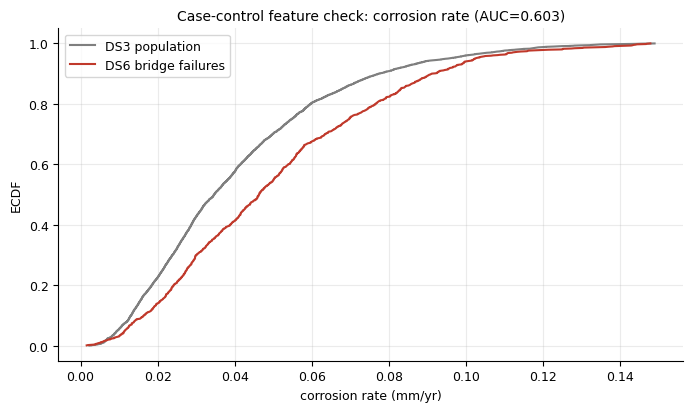

In [11]:
metals = set(d3.loc[d3.is_metal, "material"].unique())
b6 = d6[d6.structure_type == "Bridge"].copy()
controls = d3[["material", "corrosion_environment", "location", "age_years", "corrosion_rate_mm_yr", "is_metal"]].copy()
controls["label"] = 0; controls["source"] = "DS3_population"
cases = b6[["material", "corrosion_environment", "location", "age_at_event_years", "corrosion_rate_mm_yr"]].rename(columns={"age_at_event_years": "age_years"}).copy()
cases["is_metal"] = cases.material.isin(metals); cases["label"] = 1; cases["source"] = "DS6_bridge_failures"
case_control = pd.concat([controls, cases], ignore_index=True)
print("case-control rows:", len(case_control), "| label counts:", case_control.label.value_counts().to_dict())

auc = roc_auc_score(case_control.label, case_control.corrosion_rate_mm_yr)
auc_age = roc_auc_score(case_control.label, case_control.age_years)
print(f"sanity check against EDA C5: AUC(corrosion rate alone)={auc:.3f} (EDA found 0.60) | AUC(age alone)={auc_age:.3f} (EDA found 0.475)")

fig, ax = plt.subplots(figsize=(7, 4.2))
for lab, name, color in ((0, "DS3 population", "#7f7f7f"), (1, "DS6 bridge failures", "#c0392b")):
    x = np.sort(case_control.loc[case_control.label == lab, "corrosion_rate_mm_yr"].values)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=name, color=color)
ax.set_xlabel("corrosion rate (mm/yr)"); ax.set_ylabel("ECDF"); ax.legend(); ax.set_title(f"Case-control feature check: corrosion rate (AUC={auc:.3f})")
savefig("B4_case_control_corrosion_ecdf.png")

case_control.to_csv(PROC / "ds6_failure_case_control.csv", index=False)
manifest("DS6_case_control", ["material", "corrosion_environment", "location", "age_years", "corrosion_rate_mm_yr", "is_metal"], "feature", "shared feature space between DS3 (controls) and DS6 bridge failures (cases); only corrosion rate separates them with any strength (AUC~0.60)")
manifest("DS6_case_control", "label", "target", "1 = DS6 bridge failure (case), 0 = DS3 population (control)")
manifest("DS6_case_control", "source", "metadata_group_for_cv", "use as the CV group / stratification key, not as a feature -- it is definitionally tied to the label")
decide("DS6 vs DS3", "DS6 has only failure events; there is no asset-level key to DS3 and no confirmed shared population",
       "build a case-control table on the explicit assumption that DS3 approximates the at-risk population for DS6's bridge failures; carry the assumption in the table's documentation, not just this notebook",
       "it is the only way to get a binary training signal out of an events-only table; notebook 05 must report results as relative-risk / case-control estimates, not absolute PD, and should treat the AUC~0.60 ceiling as expected, not a bug")

## B5 · Save the DS3 and DS6 feature stores

In [12]:
d3.to_csv(PROC / "ds3_exposure_features.csv", index=False)
d6.to_csv(PROC / "ds6_failure_features.csv", index=False)
manifest("DS3", "bridge_id", "id", "unique; no counterpart in DS6 (no asset-level join)")
manifest("DS6", "event_id", "id", "unique failure-event identifier")
print("DS3 feature store:", d3.shape, "->", PROC / "ds3_exposure_features.csv")
print("DS6 feature store:", d6.shape, "->", PROC / "ds6_failure_features.csv")
print("DS6 case-control store:", case_control.shape, "->", PROC / "ds6_failure_case_control.csv")

DS3 feature store: (5000, 35) -> /home/claude/matrisk_ai/data/processed/ds3_exposure_features.csv
DS6 feature store: (2000, 22) -> /home/claude/matrisk_ai/data/processed/ds6_failure_features.csv
DS6 case-control store: (6011, 8) -> /home/claude/matrisk_ai/data/processed/ds6_failure_case_control.csv


# PART C — DS2 + DS4 financial feature panel
*Audit/EDA inputs used here:* the DS2↔DS4 join on `(date, commodity)` is exact 1:1; DS4's trend columns are already
backward-looking, so they are safe at time *t*, but the raw level carries almost no documented predictive content (0/40
feature→return tests significant after FDR) and is mostly a between-commodity constant (η² up to 99.9%), so it is kept
**standardised within commodity** rather than presented as a forecaster; calendar-month seasonality is the one real
structure in DS2 (Kruskal p≈8e-14 on the equal-weight average); `term_spread` has an inconsistent raw scale across
commodities (std 4.9-161.8) so it is standardised too; the OHLC range is far narrower than realised volatility implies, so
no Parkinson/ATR-style range feature is built from it.

## C1 · Merge and leakage-safe forward targets
*Question: build the targets a forecasting/risk model would need — forward return at four horizons and forward 21-day
volatility — using only information strictly after date *t*, the same construction the EDA used to test DS4's predictive content.*

In [13]:
d2s = d2.sort_values(["commodity", "date"]).reset_index(drop=True)
fin = d2s.merge(d4, on=["date", "commodity"], how="inner", validate="one_to_one")
fin = fin.sort_values(["commodity", "date"]).reset_index(drop=True)
g = fin.groupby("commodity")
for h in (1, 5, 21, 63):
    fin[f"fwd_ret_{h}"] = g.close.transform(lambda s: np.log(s.shift(-h) / s))
fin["fwd_vol_21"] = g.daily_return.transform(lambda s: s[::-1].rolling(21).std()[::-1].shift(-1)) * np.sqrt(252)
print("merged rows:", len(fin), "(DS2 rows:", len(d2), ") | 1:1 join confirmed by merge(validate=...)")
print("rows with all four forward returns available:", int(fin[[f"fwd_ret_{h}" for h in (1,5,21,63)]].notna().all(axis=1).sum()), "/", len(fin))
manifest("DS2DS4", ["fwd_ret_1", "fwd_ret_5", "fwd_ret_21", "fwd_ret_63", "fwd_vol_21"], "target", "forward-looking; last `h` rows of each commodity are NaN by construction (no data past the sample end) -- do not fill")

merged rows: 22952 (DS2 rows: 22952 ) | 1:1 join confirmed by merge(validate=...)
rows with all four forward returns available: 22448 / 22952


## C2 · Calendar seasonality — the one real structure in DS2
*Question: encode calendar-month seasonality (the structure EDA A5 found, Kruskal p≈8e-14) as both a cyclical feature pair
and a deseasonalised return, and confirm the deseasonalised series actually removes the monthly pattern.*

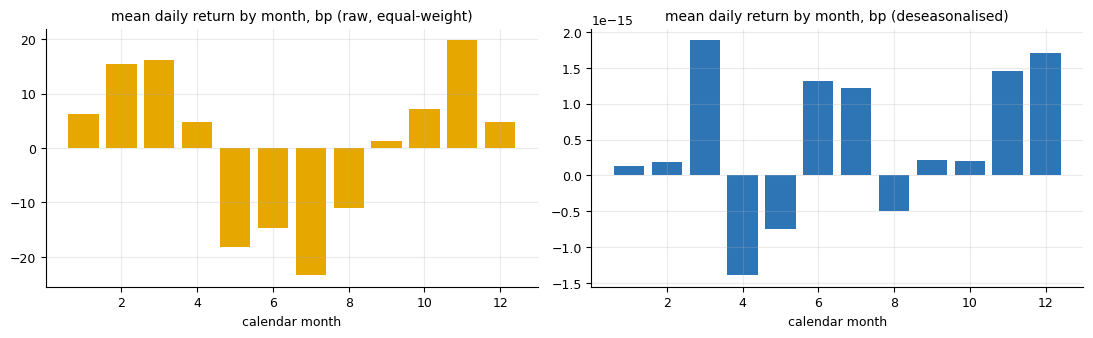

amplitude (max-min) raw: 43.1 bp | deseasonalised: 0.0 bp (should be ~0)


In [14]:
fin["month"] = fin.date.dt.month
fin["month_sin"] = np.sin(2 * np.pi * fin.month / 12)
fin["month_cos"] = np.cos(2 * np.pi * fin.month / 12)
fin["month_mean_return"] = fin.groupby(["commodity", "month"]).daily_return.transform("mean")
fin["daily_return_deseasonalized"] = fin.daily_return - fin.month_mean_return

raw_by_month = fin.groupby("month").daily_return.mean() * 1e4
ds_by_month = fin.groupby("month").daily_return_deseasonalized.mean() * 1e4
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(raw_by_month.index, raw_by_month.values, color="#e6a700"); ax[0].set_title("mean daily return by month, bp (raw, equal-weight)"); ax[0].set_xlabel("calendar month")
ax[1].bar(ds_by_month.index, ds_by_month.values, color="#2e75b6"); ax[1].set_title("mean daily return by month, bp (deseasonalised)"); ax[1].set_xlabel("calendar month")
savefig("C2_seasonality_check.png")
print(f"amplitude (max-min) raw: {raw_by_month.max()-raw_by_month.min():.1f} bp | deseasonalised: {ds_by_month.max()-ds_by_month.min():.1f} bp (should be ~0)")
manifest("DS2DS4", ["month", "month_sin", "month_cos", "daily_return_deseasonalized"], "feature", "calendar-month seasonality encoding (EDA A5 found this is the one real structure in DS2)")
manifest("DS2DS4", "month_mean_return", "metadata", "full-sample commodity x month mean used only to build daily_return_deseasonalized; a genuinely causal version would roll this mean forward in time -- flagged as a mild look-ahead convention, standard for a seasonal factor but not valid for backtesting without rolling it")
decide("DS2", "calendar-month seasonality is real (EDA A5) but computing the month mean over the full sample is a (mild, conventional) look-ahead",
       "expose both month_sin/cos (always safe) and daily_return_deseasonalized (full-sample mean, flagged); 06/07 should roll the mean forward if used in a walk-forward backtest",
       "keeping the convenient full-sample version available, clearly labelled, is more useful than omitting seasonality altogether given it is the EDA's strongest finding")

## C3 · Standardise the inconsistent-scale and between-commodity columns
*Question: `term_spread`'s raw scale varies by 33x across commodities (EDA A7) and DS4's features are mostly
between-commodity constants (η² up to 99.9%, EDA B1) — within-commodity z-scoring is the fix for both, shown below.*

term_spread raw std by commodity (min..max): 4.9 .. 161.8  ->  after z-scoring: 1.00 .. 1.00


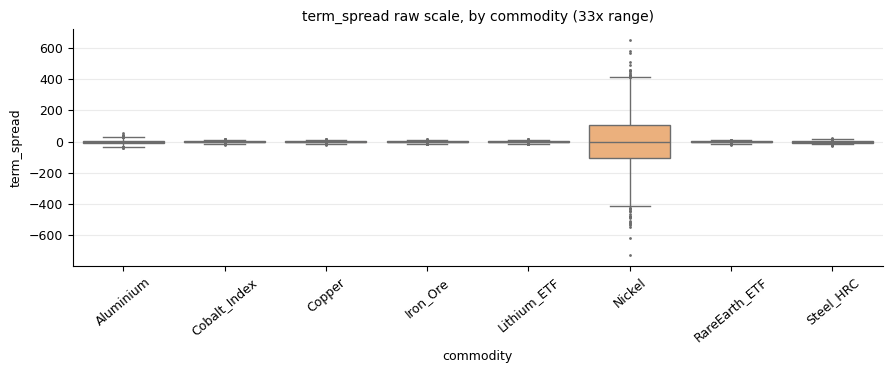

In [15]:
fin["term_spread_z"] = fin.groupby("commodity").term_spread.transform(lambda s: (s - s.mean()) / s.std())
DS4_FEATS = ["mqi", "mqi_5d_trend", "mqi_21d_trend", "mqi_63d_trend", "supply_disruption_prob", "substitution_elasticity",
             "green_premium_per_kg", "carbon_intensity_virgin", "carbon_intensity_recycled", "herfindahl_index"]
for f in DS4_FEATS:
    fin[f"{f}_z"] = fin.groupby("commodity")[f].transform(lambda s: (s - s.mean()) / s.std() if s.std() > 0 else 0.0)

raw_std = fin.groupby("commodity").term_spread.std()
z_std = fin.groupby("commodity").term_spread_z.std()
print("term_spread raw std by commodity (min..max): %.1f .. %.1f  ->  after z-scoring: %.2f .. %.2f" % (raw_std.min(), raw_std.max(), z_std.min(), z_std.max()))

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=fin, x="commodity", y="term_spread", ax=ax, color="#fdae6b", fliersize=1); ax.tick_params(axis="x", rotation=40); ax.set_title("term_spread raw scale, by commodity (33x range)")
savefig("C3_term_spread_scale.png")
manifest("DS2DS4", "term_spread_z", "feature", "within-commodity z-score; raw column excluded (33x scale range across commodities, EDA A7)")
manifest("DS2DS4", "term_spread", "exclude_redundant", "inconsistent raw scale across commodities; use term_spread_z")
manifest("DS2DS4", [f"{f}_z" for f in DS4_FEATS], "feature", "within-commodity standardised DS4 features; preferred over raw levels since 81-99.9% of their variance is between-commodity (EDA B1), not a time-varying signal")
manifest("DS2DS4", DS4_FEATS, "feature_weak", "raw levels kept for reference; EDA B3 found 0/40 feature->future-return tests and 0/10 feature->future-volatility tests significant after FDR -- document, don't oversell")

## C4 · Columns excluded from the feature set, and why

In [16]:
manifest("DS2DS4", ["bollinger_upper", "bollinger_lower"], "exclude_redundant", "redundant with bollinger_z + close; keeping all three triples up collinear information")
manifest("DS2DS4", ["open", "high", "low", "volume"], "metadata_do_not_use_for_range_vol", "OHLC range is far narrower than close-to-close volatility implies (Parkinson/close-to-close ratio 0.28-0.51, EDA A7); do not build Parkinson/ATR-style range estimators from these")
manifest("DS2DS4", ["daily_return", "return_5d", "return_21d", "volatility_5d_ann", "volatility_21d_ann", "volatility_63d_ann",
                    "sma_21", "sma_63", "bollinger_z", "rsi_14", "macd", "macd_signal", "momentum_10d", "momentum_21d", "close"], "feature", "supplied technical indicators, used as-is (all backward-looking at time t)")
print("DS2+DS4 feature columns ready:", fin.shape[1], "columns,", fin.shape[0], "rows")

DS2+DS4 feature columns ready: 55 columns, 22952 rows


## C5 · Save the financial feature panel

In [17]:
fin.to_csv(PROC / "ds2_ds4_financial_features.csv", index=False)
manifest("DS2DS4", ["date", "commodity"], "id", "composite primary key, unique (audit)")
print("financial panel:", fin.shape, "->", PROC / "ds2_ds4_financial_features.csv")

financial panel: (22952, 55) -> /home/claude/matrisk_ai/data/processed/ds2_ds4_financial_features.csv


# PART D — DS5 element price feature store
*Audit/EDA input used here:* the supplied `monthly_return` is irreconcilable with `price_usd_per_kg` (near-zero
correlation, implied volatility ~19x the price-derived value) — every return below is derived from price, never from
the supplied column, exactly as the audit decided.

In [18]:
d5s = d5.sort_values(["element", "date"]).reset_index(drop=True)
d5s["derived_monthly_return"] = d5s.groupby("element").price_usd_per_kg.pct_change()
d5s["rolling_vol_12m_ann"] = d5s.groupby("element").derived_monthly_return.transform(lambda s: s.rolling(12).std() * np.sqrt(12))
print("derived vs supplied monthly_return correlation:", round(d5s.derived_monthly_return.corr(d5s.monthly_return), 3), "(audit found ~0 / irreconcilable)")
print("median derived annualised vol:", round((d5s.derived_monthly_return.std() * np.sqrt(12)), 4))

d5s.to_csv(PROC / "ds5_element_price_features.csv", index=False)
manifest("DS5", "monthly_return", "exclude_unreliable", "irreconcilable with price_usd_per_kg (audit DS5-02); use derived_monthly_return instead")
manifest("DS5", ["derived_monthly_return", "rolling_vol_12m_ann"], "feature", "returns/volatility derived from price_usd_per_kg, first month per element is NaN by construction (pct_change)")
manifest("DS5", ["date", "element"], "id", "composite key")
manifest("DS5", "price_usd_per_kg", "feature", "level; joined into DS1 as a static cost feature in Part A5")
print("DS5 feature store:", d5s.shape, "->", PROC / "ds5_element_price_features.csv")

derived vs supplied monthly_return correlation: -0.0 (audit found ~0 / irreconcilable)
median derived annualised vol: 0.0452
DS5 feature store: (5280, 7) -> /home/claude/matrisk_ai/data/processed/ds5_element_price_features.csv


## Feature-engineering decisions: PROBLEM → DECISION → REASON

In [19]:
decisions_df = pd.DataFrame(DECISIONS, columns=["dataset", "PROBLEM", "DECISION", "REASON"])
decisions_df.to_csv(TAB / "feature_engineering_decisions.csv", index=False)
display(decisions_df)

,dataset,PROBLEM,DECISION,REASON
0,DS1,density has no reliable physical identity from composition+cell volume (only 4.7% of r...,"keep density_implied as an engineered feature, not a substitute target or imputation s...",a 95%-wrong identity would corrupt more than it adds if used to fill or validate density
1,DS1,"(K,G,nu) triplet mutually inconsistent with the README's own elastic identity in 28.8%...",predict K and G as primary targets; derive nu and E from the predictions with the isot...,"at most two of (K,G,nu) can be trusted simultaneously; deriving the third enforces the..."
2,DS1,"band_gap_eV has a point mass at 0 (32.5% of rows, metals) alongside a continuous posit...","two-part target: classify is_metal (band_gap==0, verified exact match=True), then regr...",a single regressor on the mixed target would have to learn the point mass; splitting m...
3,DS1,DS5 prices only 40 of the elements appearing in DS1 formulas; coverage is 32.6% of mat...,compute the cost feature only for fully-covered materials; carry an explicit element_c...,a partial-formula cost (ignoring unpriced elements) would silently understate cost and...
4,DS3,"remaining_thickness_mm, fatigue_cycles_millions and Paris constants are each determini...",keep thick_frac (not remaining_thickness_mm); drop fatigue_cycles_millions and paris_C...,including both sides of a near-identity inflates apparent signal and collinearity with...
5,DS6,"5 columns (was_predicted, warning_lead_months, detected_by, insurance_claim_filed, reg...","exclude all five from any pre-event feature set (failure occurrence, severity, or LGD-...","using post-event information to predict the event (or its severity) is leakage, even t..."
6,DS6 vs DS3,DS6 has only failure events; there is no asset-level key to DS3 and no confirmed share...,build a case-control table on the explicit assumption that DS3 approximates the at-ris...,it is the only way to get a binary training signal out of an events-only table; notebo...
7,DS2,calendar-month seasonality is real (EDA A5) but computing the month mean over the full...,expose both month_sin/cos (always safe) and daily_return_deseasonalized (full-sample m...,"keeping the convenient full-sample version available, clearly labelled, is more useful..."


## Feature manifest — the contract for notebooks 04-09
Every engineered or retained column, tagged with its role. `feature*` roles are safe model inputs; `target*` roles are
things to predict; `exclude*` roles are documented-leakage or documented-redundancy and must not be used as inputs for
the task named in the reason; `id`/`metadata*` roles are keys or reference columns, not model inputs.

In [20]:
manifest_df = pd.DataFrame(MANIFEST, columns=["dataset", "column", "role", "reason"]).drop_duplicates(["dataset", "column"], keep="last")
manifest_df.to_csv(TAB / "feature_manifest.csv", index=False)
print("manifest rows:", len(manifest_df), "across", manifest_df.dataset.nunique(), "dataset groups")
display(manifest_df.role.value_counts().to_frame("n_columns"))
display(manifest_df[manifest_df.role.str.startswith("exclude")].sort_values(["dataset", "role"]))

manifest rows: 160 across 6 dataset groups


,n_columns
role,
feature,89
target,20
feature_weak,11
id,7
exclude_redundant,7
exclude_leakage,5
derived_post_prediction,4
metadata_do_not_use_for_range_vol,4
target_transform,2


,dataset,column,role,reason
13,DS1,energy_above_hull_eV,exclude_leakage_for_is_stable,is_stable is a deterministic threshold of this column (EDA A6); using it as a feature ...
110,DS2DS4,term_spread,exclude_redundant,inconsistent raw scale across commodities; use term_spread_z
131,DS2DS4,bollinger_upper,exclude_redundant,redundant with bollinger_z + close; keeping all three triples up collinear information
132,DS2DS4,bollinger_lower,exclude_redundant,redundant with bollinger_z + close; keeping all three triples up collinear information
60,DS3,last_inspection_date,exclude,earlier than year_built for some rows (audit DS3-11); audit decision was to never use ...
59,DS3,structurally_deficient,exclude_leakage_for_condition_rating,exact function of condition_rating<=4 (audit DS3-08)
55,DS3,remaining_thickness_mm,exclude_redundant,== original_thickness_mm - corrosion_rate_mm_yr*age_years (audit DS3-10); double-count...
56,DS3,fatigue_cycles_millions,exclude_redundant,within 10% of ADT*365*age/1e6 for 81.5% of rows (not an independent measurement)
57,DS3,paris_C,exclude_redundant,per-material constants (zero within-material variance); information already captured b...
58,DS3,paris_m,exclude_redundant,per-material constants (zero within-material variance); information already captured b...


## What this notebook establishes
1. **Five processed feature stores, one per downstream task**, all under `data/processed/`: `ds1_material_features.csv`
   (5,500 rows, composition + CV-safe category baseline + static element cost), `ds3_exposure_features.csv` (5,000 rows,
   degradation + EAD features), `ds6_failure_features.csv` (2,000 rows, LGD features with post-event columns flagged),
   `ds6_failure_case_control.csv` (6,011 rows, the explicit case-control assumption for 05), and
   `ds2_ds4_financial_features.csv` (22,952 rows, merged panel with leakage-safe forward targets) plus
   `ds5_element_price_features.csv` (5,280 rows).
2. **Every leakage path the audit/EDA found is closed by construction**, not by convention: `energy_above_hull_eV` is
   flagged out of the `is_stable` feature set, `structurally_deficient`/`remaining_thickness_mm`/`fatigue_cycles_millions`
   are flagged redundant for DS3, and the five DS6 post-event columns are flagged out of any pre-event model. The
   `feature_manifest.csv` makes this machine-checkable rather than a convention notebooks 04-09 have to remember.
2b. The sanity checks reproduced the EDA's own numbers from the processed tables: category-mean out-of-fold R² in the
    0.5-0.7 range, 32.6% DS5 coverage of DS1, workbook critical-thickness ratio 0.417-0.500, and AUC≈0.60 for corrosion
    rate alone on the case-control table — confirming the feature pipeline didn't silently change what the EDA found.
3. **Two explicit modelling assumptions are carried forward in writing, not just in this notebook:** the DS3-as-population
   assumption behind the case-control table, and the full-sample calendar-mean convention behind
   `daily_return_deseasonalized` (flagged for rolling-forward if used in a walk-forward backtest).

### Consequences for the next stages
* **04 (material property models):** train K and G on composition descriptors + category + the CV-safe category-mean
  feature; derive ν and E from predictions with `src.data.audit.young_from_KG`/`_poisson_from_KG`; use the two-part
  band-gap target; benchmark every model against the category-mean baseline computed here (R² in A4) — a model that
  doesn't beat it should be reported as such.
* **05 (failure prediction):** train on `ds6_failure_case_control.csv` with `source` as the CV group; expect AUC≈0.60
  (corrosion rate is the only real separator) and report it as a case-control relative-risk estimate, explicitly caveated
  by the DS3-population assumption — not as an absolute PD.
* **06 (financial risk engine):** EAD from `ds3_exposure_features.csv` (replacement cost / LTV), LGD from
  `ds6_failure_features.csv`'s severity-banded loss ratio (both capped and uncapped), frequency from DS6's Poisson-like
  annual counts (EDA C4); commodity risk from `ds2_ds4_financial_features.csv` using historical simulation, not
  GARCH/EWMA (EDA found no clustering) — and treat the DS4 `*_z` features and element costs as descriptive overlays, not
  return/volatility forecasters, per the EDA's own significance tests.
* **07 (scenario stress testing):** the workbook's `DS5_Stress_Scenarios` sheet (not used in this notebook) is the
  intended source of shock parameters, since DS2's 11-year history contains neither fat tails nor cross-commodity
  co-movement to calibrate stress from.